# 使用Scikit-Learn 完成預測
### Scikit-Learn在三個面向提供支援。
1. 獲取資料:***klearn.datasets***
2. 掌握資料:***sklearn.preprocessing*** 
3. 機器學習:***sklearn Estimator API*** 

獲取資料的方式有很多種（包含檔案、資料庫、網路爬蟲、Kaggle Datasets等），<br>
其中最簡單的方式是從Sklearn import 內建的資料庫。由於其特性隨手可得且不用下載，所以我們通常叫他**玩具資料**：

# 基本架構

* 讀取資料&pre-processing
* 切分訓練集與測試集 
* 模型配適
* 預測 
* 評估(計算成績可能是誤差值或正確率或..)


In [58]:
%matplotlib inline

from sklearn import datasets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 讀取Iris資料集與資料前處理

Iris Flowers 資料集

我們在這個項目中使用 Iris Data Set，這個資料集中的每個樣本有4個特徵，1個類別。該資料集1中的樣本類別數為3類，每類樣本數目為50個，總共150個樣本。

屬性資訊：

    花萼長度 sepal length(cm)
    花萼寬度 sepal width(cm)
    花瓣長度 petal length(cm)
    花瓣寬度 petal width(cm)
    類別：
        Iris Setosa
        Iris Versicolour
        Iris Virginica

樣本特徵資料是數值型的，而且單位都相同（釐米）。

![Iris Flowers](images/iris_data.PNG)


In [3]:
iris = datasets.load_iris()
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

* 印出iris的key值與檔案位置
* 查看前10筆資料
* 查看資料型別
* 印出標註的樣本類別資料

In [4]:
print(iris.keys())

print(iris['filename'])

print(iris.data[0:10])

print(type(iris.data))

print(iris.target_names)

print(iris.target)

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
iris.csv
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]]
<class 'numpy.ndarray'>
['setosa' 'versicolor' 'virginica']
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


In [7]:
# we only take the first two features. 
X=iris.data[:,:2]
print(X.shape)
Y=iris.target
print(Y.shape)

(150, 2)
(150,)


In [8]:
#以下是組成 pandas DataFrame (也可以不用這種做)
x = pd.DataFrame(iris.data, columns=iris['feature_names'])
x.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
5,5.4,3.9,1.7,0.4
6,4.6,3.4,1.4,0.3
7,5.0,3.4,1.5,0.2
8,4.4,2.9,1.4,0.2
9,4.9,3.1,1.5,0.1


In [10]:
print('target names: '+str(iris['target_names']))

target names: ['setosa' 'versicolor' 'virginica']


In [11]:
#建立Target欄位與資料
y = pd.DataFrame(iris['target'], columns=['target'])
y.head()

,target
0,0
1,0
2,0
3,0
4,0


In [16]:
#合併資料特徵欄位與目標欄位
iris_data=pd.concat([x,y],axis=1)
iris_data=iris_data[['sepal length (cm)','petal length (cm)','target']]
iris_data.head(10)

,sepal length (cm),petal length (cm),target
0,5.1,1.4,0
1,4.9,1.4,0
2,4.7,1.3,0
3,4.6,1.5,0
4,5.0,1.4,0
5,5.4,1.7,0
6,4.6,1.4,0
7,5.0,1.5,0
8,4.4,1.4,0
9,4.9,1.5,0


In [82]:
#只選擇目標為0與1的資料
iris_data=iris_data[iris_data['target'].isin([0,1])]
iris_data
#print(iris['data'].size/len(iris['feature_names']))

,sepal length (cm),petal length (cm),target
0,5.1,1.4,0
1,4.9,1.4,0
2,4.7,1.3,0
3,4.6,1.5,0
4,5.0,1.4,0
...,...,...,...
95,5.7,4.2,1
96,5.7,4.2,1
97,6.2,4.3,1
98,5.1,3.0,1


## 切分訓練集與測試集
> train_test_split()

In [86]:
from sklearn.model_selection import train_test_split

X_train,X_test,Y_train,Y_test=train_test_split(iris_data[['sepal length (cm)','petal length (cm)']],iris_data['target'],test_size=0.3,stratify=iris_data['target'])

In [87]:
X_train.head()
#X_train.shape

,sepal length (cm),petal length (cm)
25,5.0,1.6
17,5.1,1.4
19,5.1,1.5
38,4.4,1.3
14,5.8,1.2


In [88]:
X_test.head()
#X_test.shape

,sepal length (cm),petal length (cm)
40,5.0,1.3
48,5.3,1.5
99,5.7,4.1
45,4.8,1.4
62,6.0,4.0


In [89]:
Y_train.head()
#Y_train.shape

25    0
17    0
19    0
38    0
14    0
Name: target, dtype: int64

In [90]:
Y_test.head()
#Y_test.shape

40    0
48    0
99    1
45    0
62    1
Name: target, dtype: int64

# Appendix 

>normalization和standardization是差不多的<br>
都是把數據進行前處理，從而使數值都落入到統一的數值範圍，從而在建模過程中，各個特徵量沒差別對待。<br> 
* normalization一般是把數據限定在需要的範圍，比如一般都是【0，1】，從而消除了數據量綱對建模的影響。<br> 
* standardization 一般是指將數據正態化，使平均值0方差為1.<br> 

因此normalization和standardization 是針對數據而言的，消除一些數值差異帶來的特種重要性偏見。<br>
經過歸一化的數據，能加快訓練速度，促進算法的收斂。

### Standardization (z-score)
    to compute the mean and standard deviation on a training set so as to be able to later reapply the same transformation on the testing set. 

In [91]:
def norm_stats(dfs):
    minimum = dfs.min()
    maximum = dfs.max()
    mu = dfs.mean()
    sigma = dfs.std(ddof=0)
    return (minimum, maximum, mu, sigma)


def z_score(col, stats):
    m, M, mu, s = stats
    df = pd.DataFrame(index=col.index)
    for c in col.columns:
        df[c] = (col[c]-mu[c])/s[c]
    return df

In [92]:
stats = norm_stats(X_train)
arr_x_train = np.array(z_score(X_train, stats))
arr_x_train
#arr_y_train = np.array(y_train)
#arr_x_train[:5]

array([[-0.74838327, -0.88165598],
       [-0.59430436, -1.02049944],
       [-0.59430436, -0.95107771],
       [-1.67285672, -1.08992117],
       [ 0.484248  , -1.1593429 ],
       [-0.13206764, -0.81223425],
       [-0.59430436, -1.02049944],
       [ 0.484248  ,  0.85388728],
       [-0.59430436, -0.95107771],
       [-0.59430436, -0.81223425],
       [ 0.94648472,  1.27041767],
       [ 0.17609018,  1.13157421],
       [-1.67285672, -1.02049944],
       [ 0.02201127, -1.08992117],
       [ 1.40872145,  1.13157421],
       [-0.74838327, -1.02049944],
       [-0.74838327, -0.88165598],
       [ 1.87095818,  1.47868286],
       [ 0.79240582,  1.13157421],
       [-1.3646989 , -1.02049944],
       [ 0.79240582,  1.54810459],
       [-1.05654109, -0.67339078],
       [-1.82693563, -1.22876463],
       [-0.90246218, -1.02049944],
       [ 1.25464254,  1.27041767],
       [-1.21062   , -1.08992117],
       [ 1.71687927,  1.06215247],
       [ 0.33016909, -0.95107771],
       [ 2.17911599,

## use sklearn

In [93]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(X_train)  #Compute the statistics to be used for later scaling.
print(sc.mean_)  #mean
print(sc.scale_) #standard deviation

[5.48571429 2.87      ]
[0.6490181  1.44047115]


In [94]:
#transform: (x-u)/std.
X_train_std = sc.transform(X_train)
X_train_std[:5]

array([[-0.74838327, -0.88165598],
       [-0.59430436, -1.02049944],
       [-0.59430436, -0.95107771],
       [-1.67285672, -1.08992117],
       [ 0.484248  , -1.1593429 ]])

The scaler instance can then be used on new data to transform it the same way it did on the training set:

In [95]:
X_test_std = sc.transform(X_test)
print(X_test_std[:10])

[[-0.74838327 -1.08992117]
 [-0.28614654 -0.95107771]
 [ 0.33016909  0.85388728]
 [-1.05654109 -1.02049944]
 [ 0.79240582  0.78446555]
 [-1.3646989  -1.02049944]
 [-0.90246218 -0.95107771]
 [-0.44022545 -1.02049944]
 [ 0.17609018  0.50677863]
 [-0.13206764 -1.08992117]]


you can also use fit_transform method (i.e., fit and then transform)    

In [96]:
X_train_std = sc.fit_transform(X_train)  
X_test_std = sc.fit_transform(X_test)
print(X_test_std[:10])


[[-0.71371896 -1.06479882]
 [-0.22337769 -0.92651326]
 [ 0.43041067  0.87119904]
 [-1.04061314 -0.99565604]
 [ 0.92075194  0.80205626]
 [-1.36750733 -0.99565604]
 [-0.87716605 -0.92651326]
 [-0.38682478 -0.99565604]
 [ 0.26696358  0.52548513]
 [-0.0599306  -1.06479882]]


In [97]:
print('mean of X_train_std:',np.round(X_train_std.mean(),4))
print('std of X_train_std:',X_train_std.std())

mean of X_train_std: -0.0
std of X_train_std: 1.0


## Min-Max Normaliaztion
    Transforms features by scaling each feature to a given range.
    The transformation is given by:

    X' = X - X.min(axis=0) / ((X.max(axis=0) - X.min(axis=0))
    X -> N 維資料
    


49.71558627999935
29.18688167058826


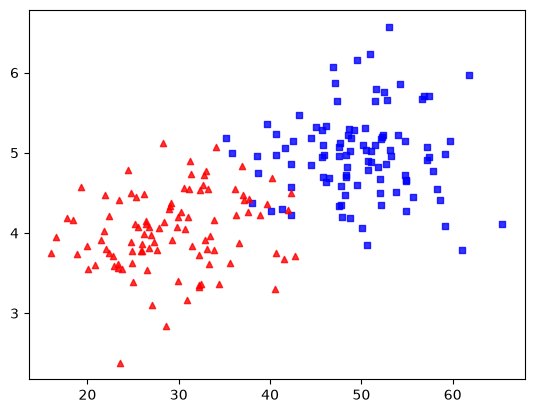

In [78]:
x1 = np.random.normal(50, 6, 100)  # np.random.normal(mu,sigma,size))
y1 = np.random.normal(5, 0.5, 100)

x2 = np.random.normal(30,6,100)
y2 = np.random.normal(4,0.5,100)
plt.scatter(x1,y1,c='b',marker='s',s=20,alpha=0.8)
plt.scatter(x2,y2,c='r', marker='^', s=20, alpha=0.8)

print(np.sum(x1)/len(x1))
print(np.sum(x2)/len(x2))

In [79]:
x_val = np.concatenate((x1,x2))
y_val = np.concatenate((y1,y2))

x_val.shape

(200,)

In [80]:
def minmax_norm(X):
    return (X - X.min(axis=0)) / ((X.max(axis=0) - X.min(axis=0)))

In [81]:
minmax_norm(x_val[:10])

array([1.        , 0.65727517, 0.        , 0.66085479, 0.46493137,
       0.7383415 , 0.02608072, 0.77760081, 0.56509329, 0.31755483])

In [37]:
from sklearn.preprocessing import MinMaxScaler
x_val=x_val.reshape(-1, 1)#1D=>2D
scaler = MinMaxScaler().fit(x_val)  # default range 0~1
print(scaler.data_max_)
print(scaler.transform(x_val)[:10])

[65.39129548]
[[0.64059701]
 [0.92326065]
 [0.79429155]
 [0.70637654]
 [0.71917368]
 [0.65926547]
 [0.59770274]
 [0.62947482]
 [0.65344586]
 [0.94707423]]
